In [1]:
import numpy as np
import os
import openmc
%matplotlib inline
import matplotlib.pyplot as plt
os.system('export OPENMC_CROSS_SECTIONS="/mnt/c/Users/joopo/OneDrive - The Pennsylvania State University/xs_libraries/endfb-viii.0-hdf5/cross_sections.xml"')

0

## U-235

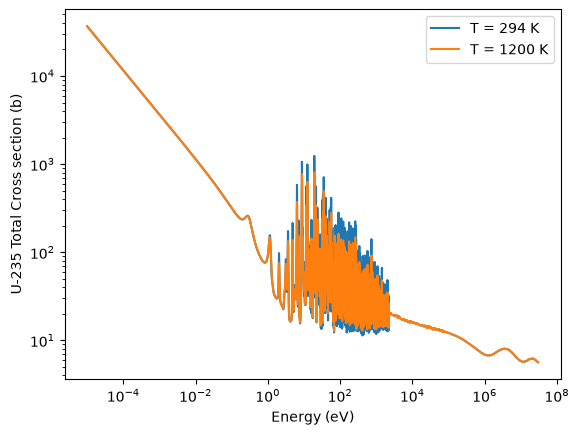

In [2]:
u235 = openmc.data.IncidentNeutron.from_hdf5('/mnt/c/Users/joopo/OneDrive - The Pennsylvania State University/xs_libraries/endfb-viii.0-hdf5/neutron/U235.h5')
total_u235 = u235[1]
energies_294_u235 = u235.energy['294K']
energies_1200_u235 = u235.energy['1200K']

u235_total_xs_294 = total_u235.xs['294K'](energies_294_u235)
u235_total_xs_1200 = total_u235.xs['1200K'](energies_1200_u235)

plt.loglog(energies_294_u235, u235_total_xs_294, label = 'T = 294 K')
plt.loglog(energies_1200_u235, u235_total_xs_1200, label = 'T = 1200 K')
plt.legend()
plt.xlabel('Energy (eV)')
plt.ylabel('U-235 Total Cross section (b)')
plt.show()


In [12]:
u235[107].xs['294K'](energies_294_u235)

array([1.432799e-02, 1.410923e-02, 1.390019e-02, ..., 8.486490e-18,
       8.486440e-18, 3.202420e-18], shape=(76027,))

## Be-9

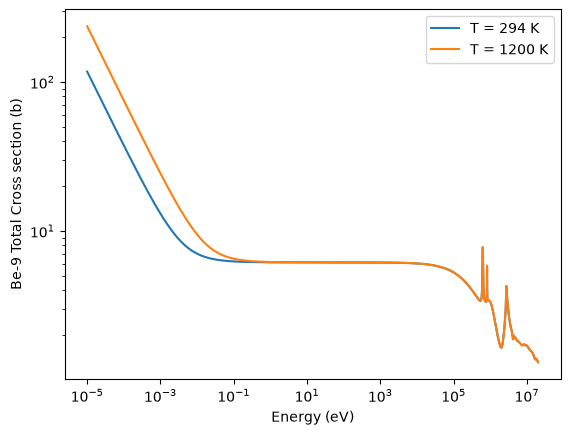

In [3]:
be9 = openmc.data.IncidentNeutron.from_hdf5('/mnt/c/Users/joopo/OneDrive - The Pennsylvania State University/xs_libraries/endfb-viii.0-hdf5/neutron/Be9.h5')
total_be9 = be9[1]
energies_294_be9 = be9.energy['294K']
energies_1200_be9 = be9.energy['1200K']

be9_total_xs_294 = total_be9.xs['294K'](energies_294_be9)
be9_total_xs_1200 = total_be9.xs['1200K'](energies_1200_be9)

plt.loglog(energies_294_be9, be9_total_xs_294, label = 'T = 294 K')
plt.loglog(energies_1200_be9, be9_total_xs_1200, label = 'T = 1200 K')
plt.legend()
plt.xlabel('Energy (eV)')
plt.ylabel('Be-9 Total Cross section (b)')
plt.show()


In [14]:
elastic_be9 = be9[2] 
absorption_be9 = be9[27]
scattering_be9 = total_be9.xs['294K'](energies_294_be9) - absorption_be9.xs['294K'](energies_294_be9)

inelastic_xs_294 = scattering_be9 - elastic_be9.xs['294K'](energies_294_be9) #scat = total - absorption; inel = scat - elastic 
elastic_xs_294 = elastic_be9.xs['294K'](energies_294_be9)

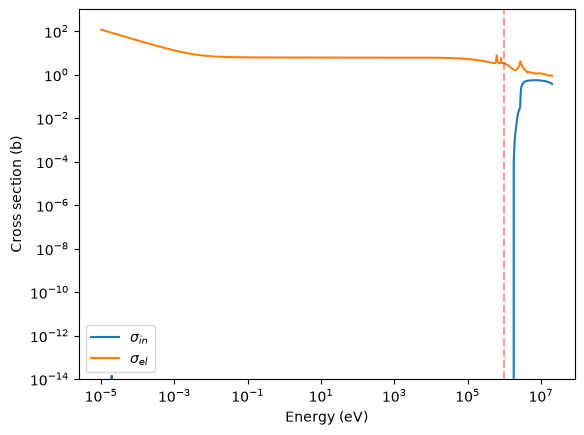

In [18]:
plt.loglog(energies_294_be9, inelastic_xs_294, label = r'$\sigma_{in}$')
plt.loglog(energies_294_be9, elastic_xs_294, label = r'$\sigma_{el}$')
#plt.loglog(energies_294_be9, be9[3].xs['294K'](energies_294_be9), label = r'$\sigma_{non-el}$')
plt.loglog(np.ones(644)*1e6, np.linspace(1e-14,1e3,644), 'r--', alpha = 0.4)
plt.legend()
plt.xlabel('Energy (eV)')
plt.ylabel('Cross section (b)')
plt.ylim(1e-14,1e3)
plt.show()


## C-12

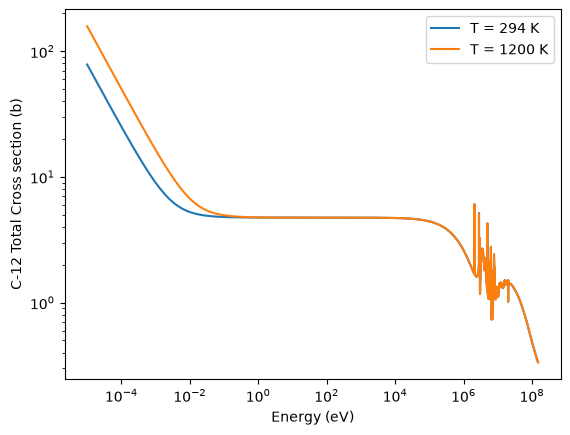

In [6]:
c12 = openmc.data.IncidentNeutron.from_hdf5('/mnt/c/Users/joopo/OneDrive - The Pennsylvania State University/xs_libraries/endfb-viii.0-hdf5/neutron/C12.h5')
total_c12 = c12[1]
energies_294_c12 = c12.energy['294K']
energies_1200_c12 = c12.energy['1200K']

c12_total_xs_294 = total_c12.xs['294K'](energies_294_c12)
c12_total_xs_1200 = total_c12.xs['1200K'](energies_1200_c12)

plt.loglog(energies_294_c12, c12_total_xs_294, label = 'T = 294 K')
plt.loglog(energies_1200_c12, c12_total_xs_1200, label = 'T = 1200 K')
plt.legend()
plt.xlabel('Energy (eV)')
plt.ylabel('C-12 Total Cross section (b)')
plt.show()

